Using Colab cache for faster access to the 'road-damage' dataset.


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

Epoch 1: 211.024
Epoch 2: 155.875
Epoch 3: 139.851
Epoch 4: 127.772
Epoch 5: 120.383
Epoch 6: 113.819
Epoch 7: 108.368
Epoch 8: 103.675
Epoch 9: 99.400
Epoch 10: 96.267
Epoch 11: 94.294
Epoch 12: 91.218
Epoch 13: 92.618
Epoch 14: 88.461
Epoch 15: 87.060
Epoch 16: 84.589
Epoch 17: 85.088
Epoch 18: 83.527
Epoch 19: 84.214
Epoch 20: 81.555
Epoch 21: 80.781
Epoch 22: 78.796
Epoch 23: 79.568
Epoch 24: 79.155
Epoch 25: 78.389
Epoch 26: 76.877
Epoch 27: 78.587
Epoch 28: 76.812
Epoch 29: 77.405
Epoch 30: 77.081
Epoch 31: 75.897
Epoch 32: 75.152
Epoch 33: 75.958
Epoch 34: 75.051
Epoch 35: 75.257
Epoch 36: 75.177
Epoch 37: 74.536
Epoch 38: 75.310
Epoch 39: 74.757
Epoch 40: 74.595

GLOBAL
Accuracy: 0.9858333333333333
F1-weighted: 0.9858221773843411
ROC-AUC: 0.9969679433288847
LogLoss: 0.11810266267615409

PER CLASS F1
Pothole : 0.9942462600690449
Alligator Crack : 0.9795918367346939
Longitudinal Crack : 0.9789227166276346
Lateral Crack : 0.9834087481146304


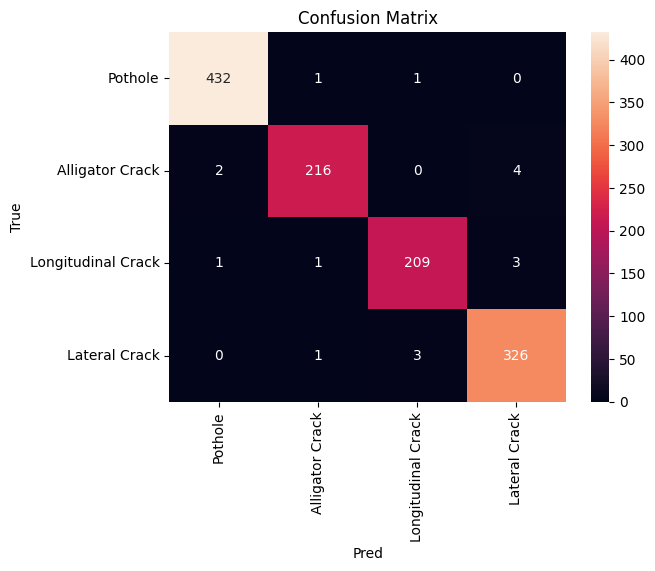

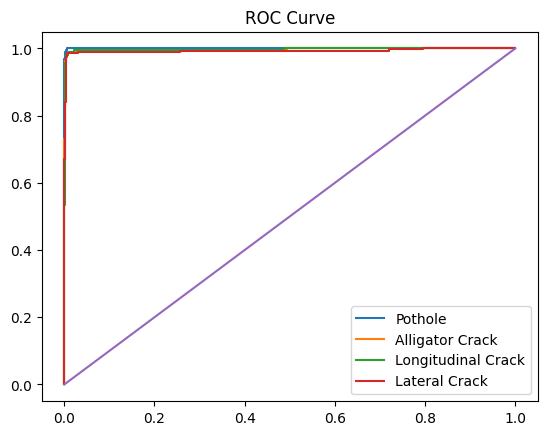

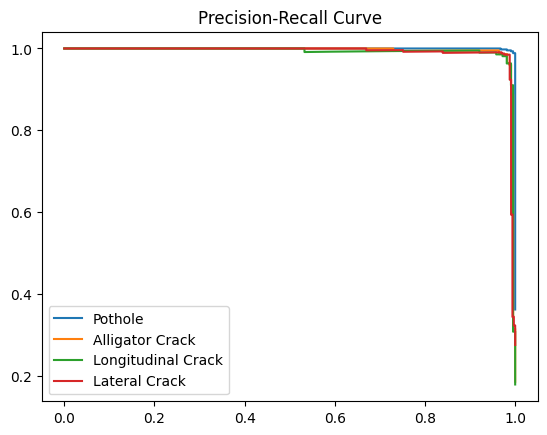

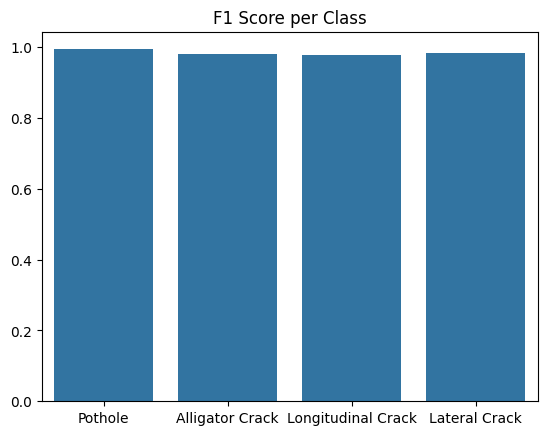

In [3]:
# =========================================================
# 1. Install
# =========================================================
!pip install -q ultralytics kagglehub scikit-learn matplotlib seaborn albumentations timm

# =========================================================
# 2. Imports
# =========================================================
import kagglehub, os, shutil, yaml, random, torch, cv2, timm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import *
from sklearn.preprocessing import label_binarize

from ultralytics import YOLO
import torch.nn as nn
import torch.nn.functional as F
import albumentations as A
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =========================================================
# 3. Dataset
# =========================================================
path = kagglehub.dataset_download("alvarobasily/road-damage")

dst = "/content/dataset"
if os.path.exists(dst):
    if os.path.islink(dst):
        os.unlink(dst)
    else:
        shutil.rmtree(dst)
os.symlink(path, dst)

# =========================================================
# 4. Split
# =========================================================
images = [f for f in os.listdir(dst) if f.endswith(".jpeg")]
random.shuffle(images)

train_imgs = images[:int(0.8*len(images))]
val_imgs   = images[int(0.8*len(images)):]

base = "/content/yolo_data"
for f in ["images/train","images/val","labels/train","labels/val"]:
    os.makedirs(f"{base}/{f}", exist_ok=True)

def move(imgs, t):
    for f in imgs:
        shutil.copy(f"{dst}/{f}", f"{base}/images/{t}/{f}")
        lbl = f"{dst}/{f.replace('.jpeg','.txt')}"
        if os.path.exists(lbl):
            shutil.copy(lbl, f"{base}/labels/{t}/{f.replace('.jpeg','.txt')}")

move(train_imgs,"train")
move(val_imgs,"val")

# =========================================================
# 5. Dataset Class
# =========================================================
names = ['Pothole','Alligator Crack','Longitudinal Crack','Lateral Crack']
nc = len(names)

train_tf = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.ShiftScaleRotate(0.1,0.1,20,p=0.6),
    A.GaussianBlur(p=0.2),
])

val_tf = None

class RoadDataset(Dataset):
    def __init__(self, img_dir, label_dir, tf=None):
        self.imgs = [f for f in os.listdir(img_dir) if f.endswith(".jpeg")]
        self.img_dir = img_dir
        self.label_dir = label_dir
        self.tf = tf

    def __len__(self): return len(self.imgs)

    def __getitem__(self, idx):
        name = self.imgs[idx]
        img = cv2.imread(f"{self.img_dir}/{name}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img,(640,640))/255.0

        label_path = f"{self.label_dir}/{name.replace('.jpeg','.txt')}"
        cls = 0
        if os.path.exists(label_path):
            cls = int(open(label_path).readline().split()[0])

        if self.tf:
            img = self.tf(image=img)['image']

        img = np.transpose(img,(2,0,1))

        return torch.tensor(img,dtype=torch.float32), torch.tensor(cls)

train_loader = DataLoader(RoadDataset(f"{base}/images/train",f"{base}/labels/train",train_tf),batch_size=16,shuffle=True)
val_loader   = DataLoader(RoadDataset(f"{base}/images/val",f"{base}/labels/val",val_tf),batch_size=16)

# =========================================================
# 6. HYBRID MODEL (YOLO Backbone + EfficientNet Fusion)
# =========================================================
yolo = YOLO("yolov8n.pt")

class HybridModel(nn.Module):
    def __init__(self, nc):
        super().__init__()

        # YOLO backbone (feature extractor)
        self.yolo_backbone = nn.Sequential(*yolo.model.model[:10])

        # Secondary CNN branch (EfficientNet)
        self.effnet = timm.create_model("efficientnet_b0", pretrained=True, num_classes=0)

        # Fusion
        self.fc = nn.Sequential(
            nn.Linear(256 + 1280, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, nc)
        )

    def forward(self,x):
        # YOLO features
        y_feat = self.yolo_backbone(x)
        y_feat = F.adaptive_avg_pool2d(y_feat,1).flatten(1)

        # EfficientNet features
        e_feat = self.effnet(x)

        fused = torch.cat([y_feat,e_feat],dim=1)
        return self.fc(fused)

model = HybridModel(nc).to(device)

# =========================================================
# 7. Loss + Optimizer
# =========================================================
class LabelSmoothingCE(nn.Module):
    def __init__(self, eps=0.1):
        super().__init__()
        self.eps = eps

    def forward(self, pred, target):
        logp = F.log_softmax(pred,dim=1)
        nll = -logp.gather(1,target.unsqueeze(1)).squeeze(1)
        smooth = -logp.mean(dim=1)
        return ((1-self.eps)*nll + self.eps*smooth).mean()

loss_fn = LabelSmoothingCE()

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=40)

# =========================================================
# 8. TRAIN
# =========================================================
EPOCHS = 40

for epoch in range(EPOCHS):
    model.train()
    total=0

    for imgs,cls in train_loader:
        imgs,cls = imgs.to(device),cls.to(device)

        out = model(imgs)
        loss = loss_fn(out,cls)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item()

    scheduler.step()
    print(f"Epoch {epoch+1}: {total:.3f}")

# =========================================================
# 9. EVALUATION
# =========================================================
model.eval()
y_true,y_pred,y_prob = [],[],[]

with torch.no_grad():
    for imgs,cls in val_loader:
        imgs = imgs.to(device)

        out = model(imgs)
        prob = torch.softmax(out,1).cpu().numpy()
        pred = np.argmax(prob,1)

        y_true.extend(cls.numpy())
        y_pred.extend(pred)
        y_prob.extend(prob)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

# =========================================================
# 10. METRICS
# =========================================================
acc = accuracy_score(y_true,y_pred)
f1  = f1_score(y_true,y_pred,average=None)
f1_w= f1_score(y_true,y_pred,average='weighted')

y_oh = label_binarize(y_true,classes=list(range(nc)))

roc = roc_auc_score(y_oh,y_prob,multi_class='ovr')
logl = log_loss(y_oh,y_prob)

print("\nGLOBAL")
print("Accuracy:",acc)
print("F1-weighted:",f1_w)
print("ROC-AUC:",roc)
print("LogLoss:",logl)

print("\nPER CLASS F1")
for i,c in enumerate(names):
    print(c,":",f1[i])

# =========================================================
# 11. CONFUSION MATRIX
# =========================================================
cm = confusion_matrix(y_true,y_pred)

plt.figure()
sns.heatmap(cm,annot=True,fmt='d',
            xticklabels=names,yticklabels=names)
plt.title("Confusion Matrix")
plt.xlabel("Pred")
plt.ylabel("True")
plt.show()

# =========================================================
# 12. ROC PER CLASS
# =========================================================
plt.figure()
for i in range(nc):
    fpr,tpr,_ = roc_curve(y_oh[:,i],y_prob[:,i])
    plt.plot(fpr,tpr,label=names[i])
plt.plot([0,1],[0,1])
plt.legend()
plt.title("ROC Curve")
plt.show()

# =========================================================
# 13. CLASS-WISE PRECISION-RECALL
# =========================================================
plt.figure()
for i in range(nc):
    p,r,_ = precision_recall_curve(y_oh[:,i],y_prob[:,i])
    plt.plot(r,p,label=names[i])
plt.legend()
plt.title("Precision-Recall Curve")
plt.show()

# =========================================================
# 14. CLASS DISTRIBUTION PERFORMANCE
# =========================================================
plt.figure()
sns.barplot(x=names,y=f1)
plt.title("F1 Score per Class")
plt.show()